# 05 · Spreading things through the network (Lectures 4–5)

Two ideas from the newer lectures, tried on our patient networks:

1. **SIR epidemic model:** start an "infection" at a few stays and let it spread along links (each infected stay infects each neighbour with chance 30% per step, recovers with chance 10%). How fast it spreads tells us about the network's shape.
2. **Cascade from patients with the outcome:** start at some stays that *have* the outcome and spread with a small chance (10%) per link. Who gets reached? If similar patients share outcomes, the reached ones should have the outcome more often than average. This is basically what Project 2's "label propagation" will do.

Plus **graph partitioning** (Lecture 4): split the network with spectral clustering and compare with the Leiden communities.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from ehrgraph.eval.aggregate import write_aggregate
from ehrgraph.netstats.spreading import cascade_reach, sir_curves, spectral_vs_leiden
from ehrgraph.netstats.task_analysis import PRIMARY_VARIANT, task_graphs_from_labels
from ehrgraph.project import setup
from ehrgraph.viz import network_figures as nf

p = setup()  # finds the data in data/omop/


nf.apply_style()
TASKS = {"guo_los": "long hospital stay", "new_hypertension": "new high blood pressure"}
nets = {
    task: task_graphs_from_labels(p.diagnoses, p.labels(task), task, n_null=1) for task in TASKS
}

data folder: ~/repos/ehrshot-patient-graphs/data/omop
results go to: ~/repos/ehrshot-patient-graphs/results/aggregate


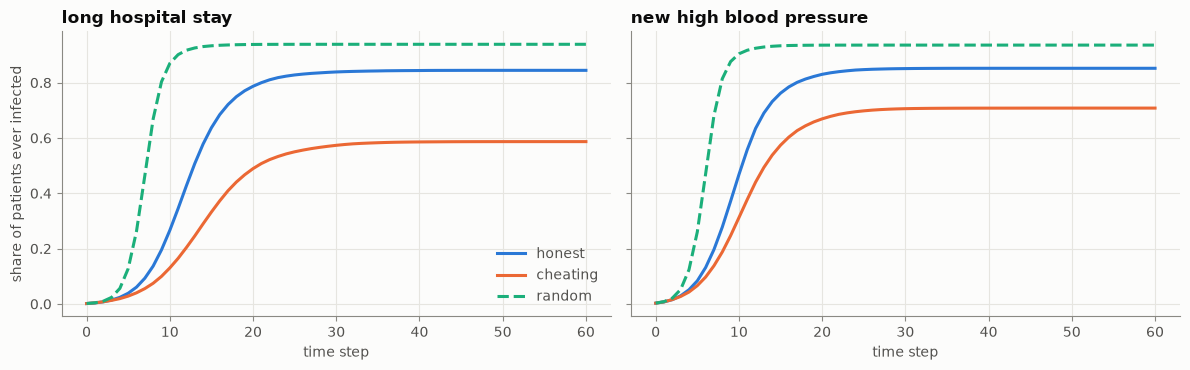

In [2]:
sir = {
    TASKS[t]: {
        name: sir_curves(n.graphs[name], beta=0.3, gamma=0.1, runs=20)
        for name in ("safe", "leaky", "null")
    }
    for t, n in nets.items()
}
fig = nf.sir_figure(sir)
nf.save(fig, p.figures / "05_sir_spreading.png")
plt.show()

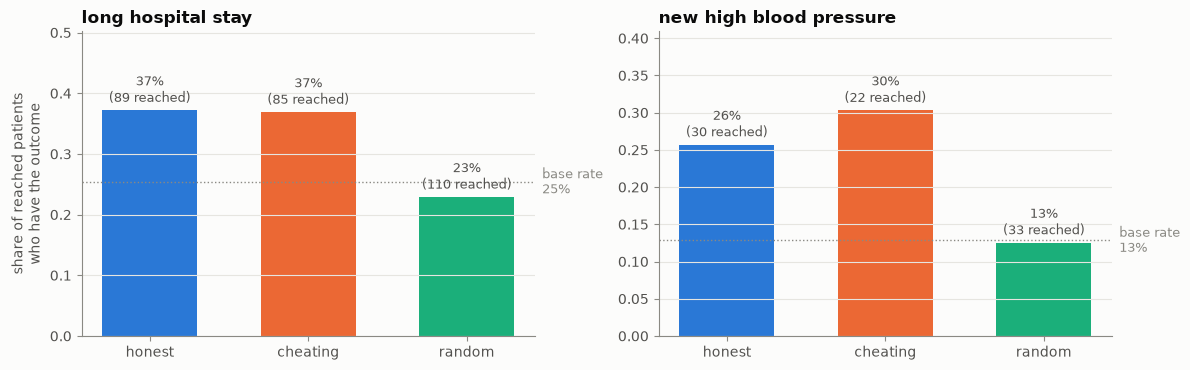

In [3]:
reach = {
    TASKS[t]: {
        name: cascade_reach(n.graphs[name], n.labels, p=0.1) for name in ("safe", "leaky", "null")
    }
    for t, n in nets.items()
}
fig = nf.cascade_figure(reach)
nf.save(fig, p.figures / "05_cascade_reach.png")
plt.show()

## Partitioning: spectral clustering vs Leiden

Spectral clustering splits the network into a fixed number of groups using the graph's eigenvectors. We try 10 groups, and as many groups as Leiden found. Higher modularity = cleaner groups; η² = how much of the outcome the groups explain.

In [4]:
parts = []
for task, n in nets.items():
    leiden_k = int(spectral_vs_leiden(n.graphs["safe"], n.labels, k=2)["n_leiden_groups_lcc"])
    for k in (10, leiden_k):
        r = spectral_vs_leiden(n.graphs["safe"], n.labels, k=k)
        parts.append(
            {
                "question": TASKS[task],
                "spectral groups": k,
                "spectral modularity": r["spectral_modularity"],
                "Leiden modularity": r["leiden_modularity_lcc"],
                "spectral η²": r["spectral_eta_squared"],
                "Leiden η²": r["leiden_eta_squared_lcc"],
                "agreement (ARI)": r["spectral_vs_leiden_ari"],
            }
        )
parts = pd.DataFrame(parts)
parts.round(3)

,question,spectral groups,spectral modularity,Leiden modularity,spectral η²,Leiden η²,agreement (ARI)
0,long hospital stay,10,0.414,0.926,0.038,0.113,0.021
1,long hospital stay,74,0.893,0.926,0.110,0.113,0.435
2,new high blood pressure,10,0.466,0.905,0.022,0.092,0.036
3,new high blood pressure,51,0.871,0.905,0.076,0.092,0.558


In [5]:
rows = []
for t in nets:
    for name, cond in (("safe", "safe"), ("leaky", "leaky"), ("null", "null_model")):
        curve = sir[TASKS[t]][name]
        r = reach[TASKS[t]][name]
        seed = 0 if name == "null" else None
        for metric, value in {
            "sir_ever_infected_t10": curve[10],
            "sir_ever_infected_t30": curve[30],
            "cascade_reached": r["cascade_reached"],
            "cascade_positive_share": r["cascade_positive_share"],
        }.items():
            rows.append(
                dict(
                    task=t,
                    condition=cond,
                    graph_variant=PRIMARY_VARIANT,
                    metric=metric,
                    value=float(value),
                    seed=seed,
                )
            )
for row in parts.itertuples():
    t = next(k for k, v in TASKS.items() if v == row.question)
    for metric, value in {
        f"spectral_k{row._2}_modularity": row._3,
        f"spectral_k{row._2}_eta_squared": row._5,
        f"spectral_k{row._2}_ari_vs_leiden": row._7,
    }.items():
        rows.append(
            dict(
                task=t,
                condition="safe",
                graph_variant=PRIMARY_VARIANT,
                metric=metric,
                value=float(value),
            )
        )
write_aggregate(rows, p.results / "spreading.csv");

## What we learned

- **Spreading is much slower on the real networks.** After 10 steps, the random network is about 87–90% infected, honest only 27% (long stay) and 47% (blood pressure). Tight clusters with few bridges slow things down, exactly what Lectures 4–5 predict. Cheating is even slower: it's more broken up.
- **Starting from patients WITH the outcome, a short cascade mostly reaches other patients with the outcome:**
  - long stay: 37% of reached patients have it, vs 25% overall and 23% on the random network
  - blood pressure: 26% honest, 30% cheating, vs 13% overall and 13% on random
  - This is the whole idea behind Project 2 (label propagation), and it already works in plain spreading.
- **Partitioning:** with only 10 spectral groups, spectral clustering is much worse than Leiden (modularity 0.41 vs 0.93). Give it as many groups as Leiden finds (74) and it gets close: 0.89, and explains about the same share of the outcome (0.110 vs 0.113). So the network really is lots of small tight groups, not a few big ones.